[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_centralfield.ipynb)


# Central field

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

from scipy.integrate import quad,solve_ivp
x=sp.symbols("x",positive=True)

Motion in a stationary central field is integrable because angular momentum is conserved. The potential depends only on the distance from the force centre:

$$
m\frac{{d}^{2}\mathbf{r}}{{dt}^{2}}=\mathbf{-}\nabla \mathbf{ }U\left(r\right)=-\frac{dU}{dr}\mathbf{\frac{\mathbf{r}}{r}}\Rightarrow m \mathbf{r}\mathbf{\times }\frac{{d}^{2}\mathbf{r}}{{dt}^{2}}=m \frac{d}{dt}\left(\mathbf{r}\mathbf{\times }\frac{d\mathbf{r}}{dt}\right)=0\\ \mathbf{M}\mathbf{=} \mathbf{r\times p = \text{const}}\tag{1}
$$

The trajectory lies in a plane perpendicular to the angular momentum $\mathbf{M}$. Energy conservation in planar polar coordinates gives

$$
E=\frac{m}{2}{\left(\frac{d\mathbf{r}}{dt}\right)}^{2}+U\left(r\right)=\frac{m}{2}\left({\left(\frac{dr}{dt}\right)}^{2}+{r}^{2}{\left(\frac{d\varphi }{dt}\right)}^{2}\right)+U\left(r\right)=\frac{m}{2}{\left(\frac{dr}{dt}\right)}^{2}+\frac{{M}^{2}}{2{mr}^{2}}+U\left(r\right)\\ M=m {r}^{2 }\frac{d\varphi }{dt}\tag{2}
$$

Radial motion is therefore equivalent to one-dimensional motion in an effective potential:

$$
{U}_{\text{eff}}=\frac{{M}^{2}}{2{mr}^{2}}+U\left(r\right)\tag{3}
$$

The first term is the centrifugal contribution associated with angular momentum. It acts as a repulsive effective force. The equations reduce to quadratures:

$$
\frac{dr}{dt}=\pm \sqrt{\frac{2}{m}\left(E-{U}_{\text{eff}}\left(r\right)\right)}, \frac{d\varphi }{dt}=\frac{M}{m {r}^{2 }}\\ \frac{d\varphi }{dr}=\frac{M/{r}^{2 }}{\sqrt{2m\left(E-{U}_{\text{eff}}\left(r\right)\right)}}\tag{4}
$$

Now the motion is determined by

$$
E\ge {U}_{\text{eff}}\left(r\right)\tag{5}
$$

The motion depends on the shape of $U_{\mathrm{eff}}$ (see the [one-dimensional systems lecture](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_eom.ipynb)). If

$$
\lim\limits_{r\to 0} {U}_{\text{eff}}=\frac{{M}^{2}}{2{mr}^{2}}+U\left(r\right)=+\infty\tag{6}
$$

falling into the centre is prevented, and there is a minimum approach distance $r_0$ (the periapsis). For suitable initial conditions:

$$
t={\int }_{{r}_{0}}^{r}\frac{dr}{\sqrt{\frac{2}{m}\left(E-{U}_{\text{eff}}\left(r\right)\right)}},  \varphi =\pm {\int }_{{r}_{0}}^{r}\frac{M/{r}^{2 }dr}{\sqrt{2m\left(E-{U}_{\text{eff}}\left(r\right)\right)}}\tag{7}
$$

For bounded motion, $r_{\min}\le r\le r_{\max}$, the condition for a closed orbit is

$$
\Delta \varphi ={\int }_{{r}_{\text{min}}}^{{r}_{\text{max}}}\frac{M/{r}^{2 }dr}{\sqrt{2m\left(E-{U}_{\text{eff}}\left(r\right)\right)}}=\pi \frac{p}{q}, p,q\in \mathbb{Z}\tag{8}
$$

and it is generally satisfied only at particular values of $E$ and $M$.

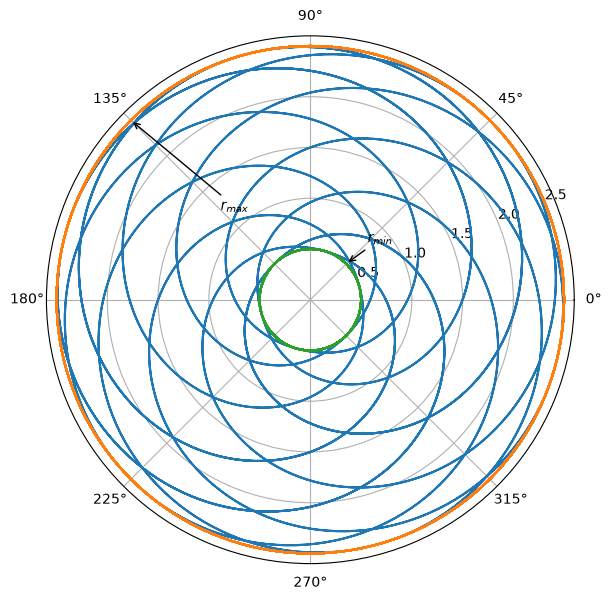

interactive(children=(IntSlider(value=2, description='p', max=7, min=2), Output()), _dom_classes=('widget-inte…

In [2]:
def show_closed_orbit(p=2):
    angle=np.linspace(0,50*np.pi,8001); radius=1.5+np.sin(3*p*angle/11)
    fig,ax=plt.subplots(figsize=(6,6),subplot_kw={'projection':'polar'},layout='constrained')
    ax.plot(angle,radius); ax.plot(angle,np.full_like(angle,2.5),'--'); ax.plot(angle,np.full_like(angle,0.5),'--')
    ax.annotate(r'$r_{max}$',xy=(3*np.pi/4,2.5),xytext=(3*np.pi/4,1.25),arrowprops={'arrowstyle':'->'})
    ax.annotate(r'$r_{min}$',xy=(np.pi/4,0.5),xytext=(np.pi/4,0.8),arrowprops={'arrowstyle':'->'})
    plt.show()
show_closed_orbit(); display(widgets.interactive(show_closed_orbit,p=widgets.IntSlider(value=2,min=2,max=7)))

There are two central potentials for which all bounded, nonsingular orbits are closed:

- The attractive Newtonian potential, $U\propto-1/r$.

- The isotropic Hooke potential, $U\propto r^2$.

(sqrt(2 - sqrt(3)), sqrt(sqrt(3) + 2))

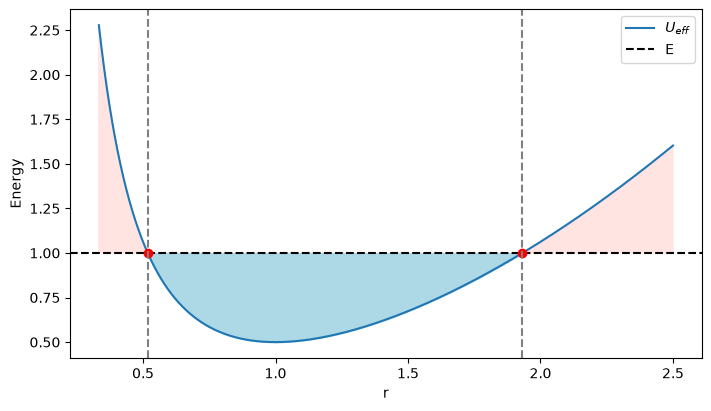

In [3]:
ueffhook=(x*x+x**-2)/4
xhmin=sp.sqrt(2-sp.sqrt(3)); xhmax=sp.sqrt(2+sp.sqrt(3))
display((xhmin,xhmax))
def plot_effective_potential(expr,energy,bounds,turning_points):
    grid=np.linspace(*bounds,1501); potential=sp.lambdify(x,expr,'numpy')(grid)
    fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
    ax.plot(grid,potential,label=r'$U_{eff}$'); ax.axhline(energy,color='black',ls='--',label='E')
    ax.fill_between(grid,potential,energy,where=potential<=energy,color='lightblue')
    ax.fill_between(grid,potential,energy,where=potential>energy,color='mistyrose')
    for point in turning_points:
        ax.plot(float(point),energy,'ro'); ax.axvline(float(point),color='gray',ls='--')
    ax.set(xlabel='r',ylabel='Energy'); ax.legend(); plt.show()
plot_effective_potential(ueffhook,1,(1/3,2.5),(xhmin,xhmax))

Angular increment (half cycle)

In [4]:
# z=x^2 converts the source integral to integral dz/[z sqrt((b-z)(z-a))].
# Its value is pi/sqrt(a*b), with a=xhmin^2 and b=xhmax^2.
hooke_integral=sp.simplify(sp.pi/(xhmin*xhmax))
display(hooke_integral,sp.simplify(hooke_integral-sp.pi)==0)

pi

True

(2 - sqrt(2), sqrt(2) + 2)

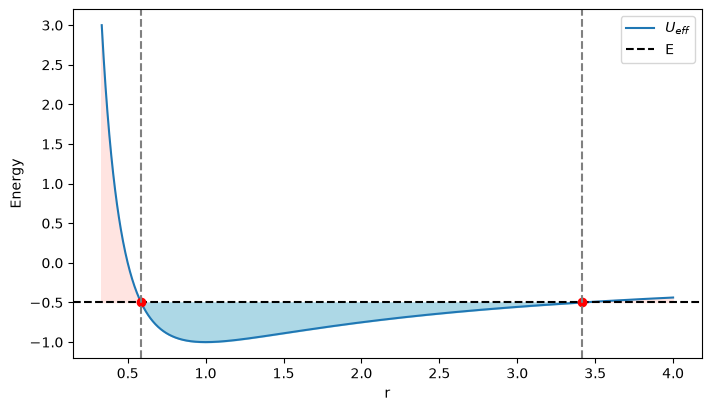

In [5]:
e0=-sp.Rational(1,2); ueffnewton=-2/x+1/x**2
xnmin=2-sp.sqrt(2); xnmax=2+sp.sqrt(2)
display((xnmin,xnmax))
plot_effective_potential(ueffnewton,float(e0),(1/3,4),(xnmin,xnmax))

Angular increment (half cycle)

In [6]:
# The numerator gains sqrt(2) after factoring E-U at the turning points.
newton_integral=sp.simplify(sp.sqrt(2)*sp.pi/sp.sqrt(xnmin*xnmax))
display(newton_integral,sp.simplify(newton_integral-sp.pi)==0)

pi

True

## Kepler’s problem

Kepler’s problem describes two bodies interacting through the Newtonian potential $U=-\Gamma/r_{12}$. It can be reduced to an equivalent one-body problem:

$$
L = \frac{{m}_{1}}{2}{\left(\frac{{d\mathbf{r}}_{1}}{dt}\right)}^{2}+\frac{{m}_{2}}{2}{\left(\frac{{d\mathbf{r}}_{2}}{dt}\right)}^{2}-U\left({r}_{12}\right)\tag{9}
$$

Momentum conservation in the centre-of-mass frame gives

$$
{m}_{1}{\mathbf{r}}_{1}+{m}_{2}{\mathbf{r}}_{2}=0\tag{10}
$$

we have

$$
L = \frac{\mu }{2}{\left(\frac{{d\mathbf{r}}_{12}}{dt}\right)}^{2}-U\left({r}_{12}\right), \mu =\frac{{m}_{1}{m}_{2}}{{m}_{1}+{m}_{2}}\\ \mu \frac{{d}^{2}{\mathbf{r}}_{12}}{{dt}^{2}}=-{\nabla }_{{r}_{12}}U\tag{11}
$$

The result is a one-body problem with reduced mass $\mu$.

For bounded motion, the trajectory is determined by

$$
\varphi =\pm {\int }_{{r}_{\text{min}}}^{r}\frac{M/{r}^{2 }dr}{\sqrt{2\mu \left(E-\left(-\frac{\gamma }{r}+\frac{{M}^{2}}{2\mu  {r}^{2}}\right)\right)}}, E<0\tag{12}
$$

A suitable change of variables evaluates this integral:

$$
{\int }_{{r}_{\text{min}}}^{r}\frac{M/{r}^{2 }dr}{\sqrt{2\mu \left(E-\left(-\frac{\gamma }{r}+\frac{{M}^{2}}{2\mu  {r}^{2}}\right)\right)}}={\int }_{{r}_{\text{min}}}^{r}\frac{1/{r}^{2 }dr}{\sqrt{-\frac{2\mu \left|E\right|}{{M}^{2}}+\frac{2\mu \gamma }{{M}^{2}}\frac{1}{r}-\frac{1}{ {r}^{2}}}}={\int }_{1/r}^{1/{r}_{\text{min}}}\frac{d\frac{1}{r}}{\sqrt{\left(\frac{1}{{r}_{\text{min}}}-\frac{1}{ r}\right)\left(\frac{1}{r}-\frac{1}{ {r}_{\text{max}}}\right)}}\\ \frac{1}{{r}_{\text{max}}}+\frac{1}{{r}_{\text{min}}}=\frac{2\mu \gamma }{{M}^{2}},\frac{1}{{r}_{\text{max}}{r}_{\text{min}}}=\frac{2\mu \left|E\right|}{{M}^{2}}\\ x=\frac{1}{r}+\frac{1}{2}\left(\frac{1}{{r}_{\text{max}}}+\frac{1}{{r}_{\text{min}}}\right)\Rightarrow {\int }_{x}^{{x}_{1}}\frac{dx}{\sqrt{{x}_{0}^{2}-{x}^{2}}}, {x}_{0}=\frac{1}{2}\left(\frac{1}{{r}_{\text{min}}}-\frac{1}{{r}_{\text{max}}}\right)=\frac{\mu \gamma }{{M}^{2}}\tag{13}
$$

The resulting trajectory is an ellipse:

$$
\varphi  = \arccos{\left(x/{x}_{0}\right)}\Rightarrow \frac{p}{r}=1+e \cos{\varphi} \\ p=\frac{1}{{x}_{0}}=\frac{{M}^{2}}{\mu \gamma }, e=\sqrt{1-\frac{2\left|E\right|{M}^{2}}{\mu  {\gamma }^{2}}}\tag{14}
$$

Here $e$ is the eccentricity. We can also find an equation for $r\left(t\right)$:

$$
t={\int }_{{r}_{0}}^{r}\frac{dr}{\sqrt{\frac{2}{\mu }\left(E-\left(-\frac{\gamma }{r}+\frac{{M}^{2}}{2\mu  {r}^{2}}\right)\right)}}=\sqrt{\frac{\mu }{2\left|E\right|}}{\int }_{{r}_{0}}^{r}\frac{r dr}{\sqrt{-{r}^{2}+\frac{\gamma }{\left|E\right|}r-\frac{{M}^{2}}{2\mu \left|E\right|}}}=\\ \sqrt{\frac{\mu }{2\left|E\right|}}{\int }_{{r}_{0}}^{r}\frac{d\left(r-\frac{\gamma }{2\left|E\right|}\right)}{\sqrt{{a}^{2}{e}^{2}-{\left(r-\frac{\gamma }{2\left|E\right|}\right)}^{2}}}, a=\frac{\gamma }{2\left|E\right|}\tag{15}
$$

using the substitution

$$
u=\left(r-\frac{\gamma }{2\left|E\right|}\right)\tag{16}
$$

which gives the following parametric form:

$$
u=\left(r-\frac{\gamma }{2\left|E\right|}\right)\Rightarrow  t=\sqrt{\frac{\mu  {a}^{3}}{\gamma }}\left(u-e \sin{u}\right), r=a\left(1-e \cos{u}\right)\tag{17}
$$

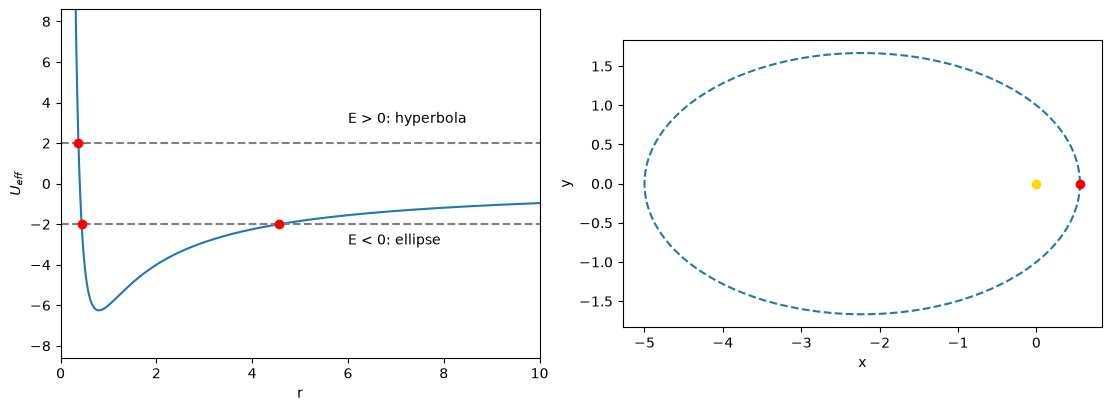

In [7]:
ueff=4/x**2-10/x
x11=(-5+sp.sqrt(33))/2
x1=(5-sp.sqrt(17))/2; x2=(5+sp.sqrt(17))/2
e0=0.8
period=quad(lambda angle:1/(1+e0*np.cos(angle))**2,0,2*np.pi,epsabs=1e-10)[0]
t0=3*period
orbit_solution=solve_ivp(lambda time,phase:[(1+e0*np.cos(phase[0]))**2],(0,t0),[0.0],
                         method='DOP853',rtol=1e-11,atol=1e-12,dense_output=True)
if not orbit_solution.success: raise RuntimeError(orbit_solution.message)
def show_kepler(time):
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    radius=np.linspace(0.05,10,1000); potential=4/radius**2-10/radius
    axes[0].plot(radius,potential); axes[0].axhline(-2,ls='--',color='gray'); axes[0].axhline(2,ls='--',color='gray')
    axes[0].plot([float(x11),float(x1),float(x2)],[2,-2,-2],'ro')
    limit=2*abs(float(ueff.subs(x,(2*x1+x2)/3)))
    axes[0].set(xlim=(0,10),ylim=(-limit,limit),xlabel='r',ylabel=r'$U_{eff}$')
    axes[0].text(6,-3,'E < 0: ellipse'); axes[0].text(6,3,'E > 0: hyperbola')
    angle=np.linspace(0,2*np.pi,801); rgrid=1/(1+e0*np.cos(angle))
    axes[1].plot(rgrid*np.cos(angle),rgrid*np.sin(angle),'--')
    phase=orbit_solution.sol(time)[0]; rnow=1/(1+e0*np.cos(phase))
    axes[1].plot(rnow*np.cos(phase),rnow*np.sin(phase),'ro'); axes[1].plot(0,0,'o',color='gold')
    axes[1].set(aspect='equal',xlabel='x',ylabel='y'); plt.show()
kepler_controls=animate_parameter(show_kepler,0,t0,0,0.2,'t')

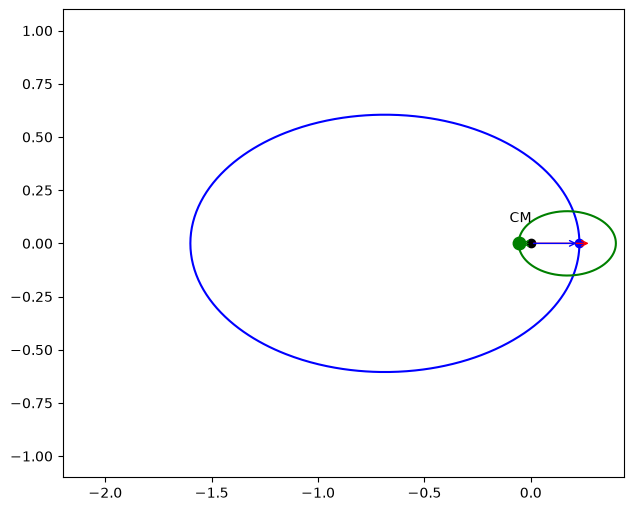

In [8]:
m1=0.2; m2=1-m1; ex=0.75; r0=0.5
def relative_position(angle):
    return r0*np.array([np.cos(angle),np.sin(angle)])/(1+ex*np.cos(angle))
def show_two_body(time):
    angle=np.linspace(0,2*np.pi,801); orbit=relative_position(angle)
    # The original demonstration reuses the previous e0=0.8 time solution.
    phase=orbit_solution.sol(time)[0]; relative=relative_position(phase)
    first=m2*relative; second=-m1*relative
    fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
    ax.plot(*(m2*orbit),color='blue'); ax.plot(*(-m1*orbit),color='green')
    trail=relative_position(np.linspace(0.01,phase,500)); ax.plot(*trail,'r--')
    ax.plot(0,0,'ko'); ax.text(-0.1,0.1,'CM')
    for position,color,size in [(relative,'red',0),(first,'blue',6),(second,'green',9)]:
        ax.annotate('',xy=position,xytext=(0,0),arrowprops={'arrowstyle':'->','color':color})
        if size: ax.plot(*position,'o',color=color,ms=size)
    ax.set(xlim=(-1.1*r0/(1-ex),1.1*max(r0/(1+ex),m1*r0/(1-ex))),ylim=(-1.1*r0/(2*(1-ex)),1.1*r0/(2*(1-ex))),aspect='equal')
    plt.show()
two_body_controls=animate_parameter(show_two_body,0,24*np.pi,0,0.2,'t')

In [9]:
# The source stores the same two-body widget again as an Input-style cached box.
display(widgets.VBox([widgets.HBox([two_body_controls[1],two_body_controls[0]]),two_body_controls[2]]))

### Problem

Draw the trajectories for $E\ge0$.

## The Laplace–Runge–Lenz vector

Energy and angular momentum do not fix the orientation of the ellipse’s major axis in its orbital plane. The closed Kepler orbits and absence of periapsis precession suggest another conserved vector that specifies this orientation.

$$
\frac{d}{d t}\left(\mathbf{p \times L}\right)=-\frac{\gamma }{{r}^{3}}\mathbf{r\times \left(r\times p\right)}=\mu  \gamma \left(\mathbf{\frac{\mathbf{\dot{r}}}{r}}-\frac{\mathbf{r} \left( \mathbf{r\cdot \dot{r}}\right)}{{r}^{3}}\right)=\mu  \gamma \frac{d}{d t}\left(\mathbf{\frac{\mathbf{r}}{r}}\right)\\ \frac{d}{dt}\left(\mathbf{p \times L}-\mu  \gamma  \mathbf{\frac{\mathbf{r}}{r}}\right)\mathbf{=}\mathbf{0  \Rightarrow  R} = \mathbf{p \times L}-\mu  \gamma  \mathbf{\frac{\mathbf{r}}{r}}\mathbf{=}\mathbf{\text{const}}\\ {R}^{2}=2\mu  H {L}^{2}+{\gamma }^{2}{\mu }^{2}={\gamma }^{2}{\mu }^{2} {e}^{2}\Rightarrow R=\gamma  \mu  e\tag{18}
$$

The orbit equation also follows directly from the expression for $\mathbf{R}$:

$$
\mathbf{R\cdot r}\mathbf{ }\mathbf{=}\mathbf{ }R r \cos{\mathbf{\varphi }}\mathbf{ }\mathbf{=}\mathbf{ }{\mathbf{L}}^{2}-\mu  \gamma  r\Rightarrow r=\frac{p}{1+e \cos{\varphi} }\\ p=\frac{{\mathbf{L}}^{2}}{R}, e=\frac{R}{\mu \gamma }\tag{19}
$$

For a circular orbit, $e=0$ and $\mathbf{R}=0$.

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)